In [ ]:


# Steps

# 0. Preprocess + EDA + Feature Selection
# 1. Extract input and output cols
# 2. Scale the values
# 3. Train test split
# 4. Train the model
# 5. Evaluate the model/model selection
# 6. Deploy the model



In [ ]:
import pandas as pd

url = "https://raw.githubusercontent.com/campusx-official/placement-project-logistic-regression/main/placement.csv"

df = pd.read_csv(url)

df.head()

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0


In [ ]:
df.head()

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0


In [ ]:
df.shape

(100, 4)

In [ ]:


import numpy as np
import pandas as pd



In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  100 non-null    int64  
 1   cgpa        100 non-null    float64
 2   iq          100 non-null    float64
 3   placement   100 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 3.3 KB


In [ ]:
#this is preprocessing we just remove unwanted column

df = df.iloc[:,1:]



In [ ]:
df.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


In [ ]:
import matplotlib.pyplot as plt

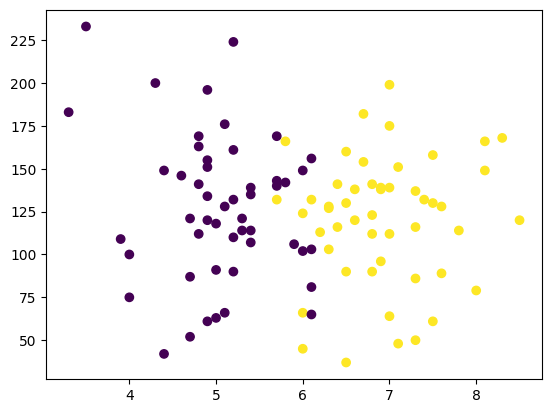

In [ ]:


plt.scatter(df['cgpa'],df['iq'],c=df['placement'])



In [ ]:


X = df.iloc[:,0:2]
y = df.iloc[:,-1]



In [ ]:
X

,cgpa,iq
0,6.8,123.0
1,5.9,106.0
2,5.3,121.0
3,7.4,132.0
4,5.8,142.0
...,...,...
95,4.3,200.0
96,4.4,42.0
97,6.7,182.0
98,6.3,103.0


In [ ]:
y.shape


(100,)

In [ ]:


from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.1)



In [ ]:

X_train

,cgpa,iq
28,5.2,90.0
55,7.8,114.0
66,6.9,96.0
58,8.0,79.0
67,5.0,118.0
...,...,...
96,4.4,42.0
82,6.5,37.0
74,6.7,154.0
50,3.5,233.0


In [ ]:


y_train



,placement
28,0
55,1
66,1
58,1
67,0
...,...
96,0
82,1
74,1
50,0


In [ ]:
X_test

,cgpa,iq
51,4.8,141.0
17,3.3,183.0
12,5.4,139.0
22,4.9,120.0
21,7.1,151.0
25,5.0,91.0
43,6.8,141.0
30,7.6,128.0
97,6.7,182.0
65,8.1,166.0


In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:

scaler = StandardScaler()

In [ ]:


X_train = scaler.fit_transform(X_train)



In [ ]:

X_train



array([[-0.72129161, -0.77670646],
       [ 1.64260526, -0.1809373 ],
       [ 0.82433326, -0.62776417],
       [ 1.82444348, -1.04976732],
       [-0.90312983, -0.08164244],
       [ 1.36984793, -1.49659419],
       [ 0.00606127, -0.47882188],
       [ 0.2788186 ,  0.14177099],
       [ 0.09698038, -0.45399816],
       [-0.26669606,  0.53895043],
       [ 0.55157593,  0.41483186],
       [-1.81232093, -0.52846931],
       [-0.99404894,  0.73754015],
       [ 0.36973771, -0.13128987],
       [ 0.00606127,  0.68789272],
       [ 1.27892882,  0.26588957],
       [ 0.46065682,  0.21624214],
       [ 0.46065682,  0.96095358],
       [-0.53945339, -0.1809373 ],
       [ 1.46076704, -0.80153017],
       [ 0.46065682, -0.77670646],
       [ 0.91525237, -1.42212304],
       [ 1.36984793,  0.21624214],
       [-0.17577695,  1.10989587],
       [ 1.18800971, -0.13128987],
       [ 0.00606127, -1.89377362],
       [-0.6303725 , -0.1809373 ],
       [ 2.27903903, -0.03199501],
       [-0.53945339,

In [ ]:
X_test = scaler.transform(X_test)

In [ ]:


X_test



array([[-1.08496805,  0.489303  ],
       [-2.4487547 ,  1.53189902],
       [-0.53945339,  0.43965557],
       [-0.99404894, -0.03199501],
       [ 1.00617149,  0.73754015],
       [-0.90312983, -0.75188274],
       [ 0.73341415,  0.489303  ],
       [ 1.46076704,  0.16659471],
       [ 0.64249504,  1.50707531],
       [ 1.91536259,  1.10989587]])

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:


clf = LogisticRegression()



In [ ]:


# model training
clf.fit(X_train,y_train)



LogisticRegression()

In [ ]:


y_pred = clf.predict(X_test)



In [ ]:


y_test



,placement
51,0
17,0
12,0
22,0
21,1
25,0
43,1
30,1
97,1
65,1


In [ ]:


from sklearn.metrics import accuracy_score



In [ ]:
accuracy_score(y_test,y_pred)

1.0

In [ ]:
from mlxtend.plotting import plot_decision_regions

<Axes: >

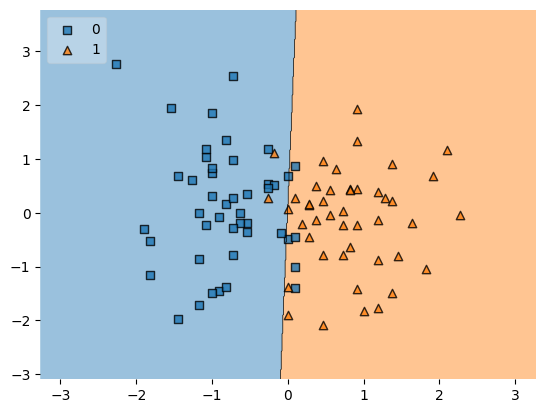

In [ ]:
plot_decision_regions(X_train, y_train.values, clf=clf, legend=2)

In [ ]:
import pickle

In [ ]:
pickle.dump(clf,open('model.pkl','wb'))